# ENSP355 | AI in Cyber Security — Lab 3
## Classifying Cyber Activity Using a Simple Neural Network
K.R. Mangalam University • School of Engineering & Technology • 2026-27

**Platform:** Google Colab / Python  |  **CO4**  |  **Total marks:** 50

> **Running on Google Colab:** upload `simple_cyber_activity.csv` (from the `data/` folder) using the Files panel, then run all cells.

## Q1. CNN, RNN/LSTM and GAN Concept Matching (5 marks)

**Aim:** To connect three deep-learning families with suitable cyber-security data and applications.

| Model | Suitable Data | Cyber-Security Example |
|---|---|---|
| CNN | Images / grid-like data | Malware image classification (binary file converted to a grayscale image); packet-matrix analysis |
| RNN / LSTM | Sequences / logs / time series | Sequential intrusion or authentication-log analysis; detecting suspicious login-event sequences |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples to augment a small / imbalanced dataset |
| Dense Network | Small numeric feature table | Normal/Attack classification in this lab |

**Why a dense network is used here:** the input is a small table of only **four numeric features** (`failed_logins`, `login_hour`, `new_device`, `data_transfer_mb`). It has no image-like grid structure (CNN not needed) and no ordered sequence (RNN/LSTM not needed), so a simple fully-connected (dense) network is the correct, lightweight choice.

## Q2. Dataset Preparation, Split and Normalization (5 marks)

**Aim:** To load the dataset, separate inputs and label, split the data and standardize numeric features.

- Label: **0 = Normal, 1 = Attack**
- `StandardScaler` rescales each feature to mean 0 and standard deviation 1.
- The scaler is **fitted on training data only**, then reused for testing data and for new records (this avoids data leakage).

In [1]:
import os, random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

random.seed(42)
np.random.seed(42)

# Find the CSV whether running locally (data/ folder) or on Colab (same folder)
for p in ['simple_cyber_activity.csv', 'data/simple_cyber_activity.csv', '../data/simple_cyber_activity.csv']:
    if os.path.exists(p):
        CSV = p
        break
else:
    raise FileNotFoundError('Upload simple_cyber_activity.csv first')

df = pd.read_csv(CSV)
features = [
    'failed_logins', 'login_hour',
    'new_device', 'data_transfer_mb'
]
X = df[features]
y = df['label']

print('Class counts (0 = Normal, 1 = Attack):')
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training shape:', X_train_scaled.shape)
print('Testing shape:', X_test_scaled.shape)

Class counts (0 = Normal, 1 = Attack):
label
0    50
1    50
Name: count, dtype: int64
Training shape: (75, 4)
Testing shape: (25, 4)


**Normalization (one sentence):** Standardization puts all features on a comparable scale so that a large-valued feature such as `data_transfer_mb` does not dominate smaller-valued ones like `new_device` only because of its magnitude.

## Q3. Build and Train the Neural Network (10 marks)

**Aim:** To build a 4-8-4-1 dense neural network and train it for 20 epochs.

- Input layer: 4 features → Hidden layers: 8 and 4 ReLU neurons → Output: 1 sigmoid neuron (probability of Attack)
- Loss: binary cross-entropy | Optimizer: Adam | Metric: accuracy

In [2]:
import tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

I0000 00:00:1794896621.677932    1215 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794896621.710608    1215 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794896622.799565    1215 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)
print(f"Final training accuracy  : {history.history['accuracy'][-1]*100:.2f}%")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]*100:.2f}%")

Epoch 1/20


1/8 ━━━━━━━━━━━━━━━━━━━━ 4s 583ms/step - accuracy: 0.6250 - loss: 0.7312

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5333 - loss: 0.7044 - val_accuracy: 0.3333 - val_loss: 0.7450


Epoch 2/20


1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.6250 - loss: 0.7082

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5500 - loss: 0.6892 - val_accuracy: 0.3333 - val_loss: 0.7275


... (51 outputs left out)

Epoch 20/20


1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 1.0000 - loss: 0.4457

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8667 - loss: 0.4959 - val_accuracy: 0.7333 - val_loss: 0.5507


Final training accuracy  : 86.67%
Final validation accuracy: 73.33%


**Definitions**
- **Epoch:** one complete pass of the model through the entire training dataset.
- **Batch size:** the number of training samples processed before the weights are updated (here 8).
- **Parameters:** 40 + 36 + 5 = **81 trainable parameters** (Dense layers: 4×8+8, 8×4+4, 4×1+1).

## Q4. Accuracy/Loss Curves and Test Evaluation (10 marks)

**Aim:** To plot learning curves, calculate test accuracy and interpret whether the model learned usefully.

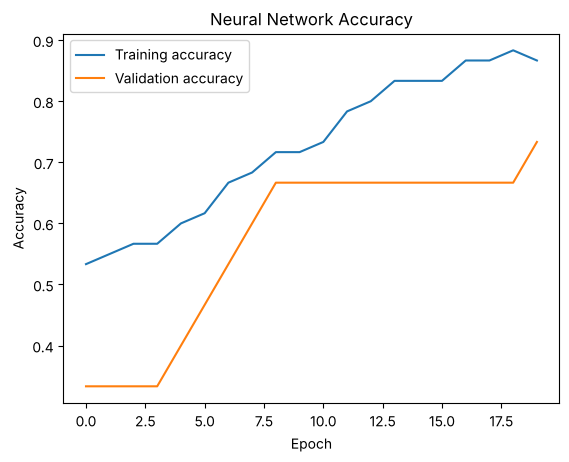

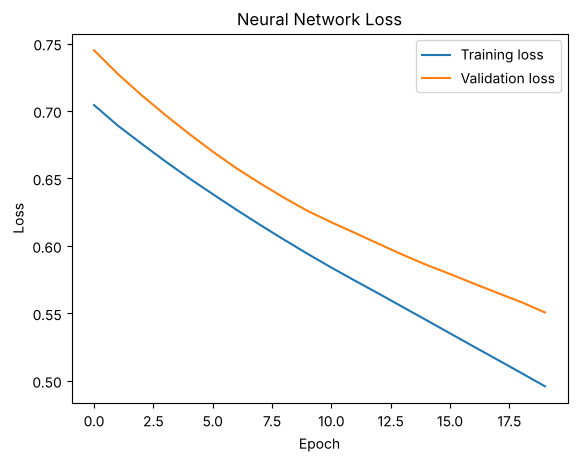

Test accuracy: 88.00%
Test loss: 0.4761


In [4]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)
print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

**Interpretation of the curves**

Training loss falls steadily and training accuracy rises from about 53% to about 87% over 20 epochs, so the network is clearly **learning** the pattern separating normal from attack activity. Validation accuracy starts low, climbs and then plateaus, finishing a little below training accuracy (about 73%). The training/validation gap is modest and the validation loss is still decreasing, so there is **no strong overfitting**; the gap mainly reflects the very small validation set (only 15 records, where one record changes accuracy by ~6.7%). The model is still slightly **under-trained** after 20 epochs and would likely improve with more epochs or more data. The final **test accuracy of 88%** on unseen data confirms that the model generalizes usefully.

## Q5. New Predictions and Decision Tree Comparison (10 marks)

**Aim:** To predict three new records and compare the neural network with a Decision Tree trained on the same split.
The neural-network probability is converted to **Attack when it is ≥ 0.50**.

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

new_records = pd.DataFrame([
    {'failed_logins': 0, 'login_hour': 11,
     'new_device': 0, 'data_transfer_mb': 35},
    {'failed_logins': 7, 'login_hour': 1,
     'new_device': 1, 'data_transfer_mb': 250},
    {'failed_logins': 2, 'login_hour': 23,
     'new_device': 1, 'data_transfer_mb': 850}
])

new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()
new_records['nn_probability'] = probabilities.round(3)
new_records['nn_prediction'] = np.where(
    probabilities >= 0.50,
    'Attack',
    'Normal'
)

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

new_records['tree_prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack',
    'Normal'
)

print(f'Neural-network accuracy: {test_accuracy * 100:.2f}%')
print(f'Decision-tree accuracy: {tree_accuracy * 100:.2f}%')
display(new_records)

Neural-network accuracy: 88.00%
Decision-tree accuracy: 92.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.404,Normal,Normal
1,7,1,1,250,0.828,Attack,Attack
2,2,23,1,850,0.603,Attack,Attack


**Agreement / disagreement analysis**

| Record | Description | NN | Decision Tree | Result |
|---|---|---|---|---|
| 1 | 0 failed logins, 11:00, known device, 35 MB | Normal (0.404) | Normal | Agree |
| 2 | 7 failed logins, 01:00, new device, 250 MB | Attack (0.828) | Attack | Agree |
| 3 | 2 failed logins, 23:00, new device, 850 MB | Attack (0.603) | Attack | Agree |

All three records receive the **same label from both models**, which increases confidence in the predictions. Record 3 has a probability of 0.603, only moderately above the 0.50 threshold, so the neural network is less certain there; the very large 850 MB transfer on a new device late at night is the main driver, and it should still be reviewed by an analyst.

**Why a simpler model may be selected:** here the Decision Tree is **more accurate (92% vs 88%)** and is **explainable** — its rules (e.g. new device + large transfer + failed logins) can be read and justified to a security analyst, whereas the neural network is a black box. It is also faster to train, needs no scaling and is easier to audit, so for a small tabular dataset the Decision Tree is the better choice.

> Note: exact numbers can vary slightly between TensorFlow versions/hardware, so re-check the text above against your own run output.

## Conclusion
A 4-8-4-1 dense neural network trained on normalized cyber-activity features learned to separate Normal and Attack records (test accuracy ≈ 88%). A Decision Tree trained on the same split performed slightly better (≈ 92%) and is directly explainable, so on this small numeric dataset the simpler model is preferable. CNN/RNN/GAN architectures would be chosen only when the data are images, sequences or need synthetic generation.